In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Geometric time smearing: how much duration a BOXCARS mask adds, and removing it.

In a non-collinear BOXCARS geometry the three input beams reach the interaction
plane with tilted pulse fronts, so the relative arrival time between arms varies
across the focal spot and the spectrometer averages over it. If the retrieval does
not model that instrument response, the free pulse absorbs it and the retrieved
duration comes out too long.

This example, for an example deep-UV mask (1 mm holes, 0.5 mm edge to edge, at
260 nm):

* builds the smearing kernel from the mask geometry alone (the focal length
  cancels, so it never appears),
* synthesises a trace from a known 1 fs pulse *with* the kernel,
* retrieves it three ways — kernel modelled, kernel ignored, kernel strength
  fitted — and reports the duration inflation,
* sweeps the mask ratio d/D, a controlled change in this reduced model; a real
  instrument can also change its illumination and collection when mask spacing changes,
* sweeps the slab thickness, and
* saves the comparison figure.

Every offset below is quoted as *smeared minus clean* at the same settings, so the
retrievals can still have different residual optimisation errors.

Run::

    uv run python examples/example_geometric_smearing.py

Writes ``geometric_smearing.png`` to the working directory.
"""

from __future__ import annotations

import matplotlib
import numpy as np

matplotlib.use("Agg")

# Imported after `matplotlib.use`, which only takes effect before pyplot binds a
# backend -- hence the E402 suppressions.
import matplotlib.pyplot as plt  # noqa: E402 - must follow matplotlib.use above

import croak  # noqa: E402 - imports pyplot transitively; see the note above
from croak.maths import wlfreq  # noqa: E402 - see the note above
from croak.smearing import square_boxcars_kernel  # noqa: E402 - see the note above

# --- an example deep-UV instrument ---------------------------------------------
WAVELENGTH = 260e-9  # carrier (m)
HOLE_DIAMETER = 1.0e-3  # mask hole diameter D (m)
HOLE_SPACING = 0.5e-3  # edge-to-edge gap between adjacent holes (m)
INTERACTION = "pg"  # TG-FROG is retrieved with the PG signal operator

# --- the pulse under test -----------------------------------------------------
# Short enough that a sub-femtosecond blur matters, on a grid fine enough to
# resolve it and a delay axis wide enough for the delay-axis convolution.
TRUE_FWHM = 1.0e-15
GRID_POINTS = 256
TIME_STEP = 0.12e-15
DELAY_SPAN = 12e-15
DELAY_POINTS = 81
MAXITERS = 800

# Mask spacings for the mask discriminator (m, edge to edge).
SPACINGS = (0.0, 0.5e-3, 1.0e-3, 1.5e-3)
# Slab thicknesses for the thickness sweep (m).
THICKNESSES = (0.0, 10e-6, 20e-6, 40e-6)
MATERIAL = "SiO2"


def kernel_for(spacing: float):
    """Square-BOXCARS kernel for a given edge-to-edge hole spacing."""
    return square_boxcars_kernel(
        INTERACTION,
        hole_diameter=HOLE_DIAMETER,
        hole_spacing=spacing,
        wavelength=WAVELENGTH,
    )


def mask_ratio(spacing: float) -> float:
    """Mask ratio d/D for a given edge-to-edge spacing."""
    return 0.5 * (spacing + HOLE_DIAMETER) / HOLE_DIAMETER


def banner(text: str) -> None:
    """Print a section heading."""
    print(f"\n{text}\n{'-' * len(text)}")


def main() -> None:
    """Run the three retrievals and the two sweeps."""
    grid = croak.Grid(GRID_POINTS, dt=TIME_STEP)
    ew = croak.gaussian_pulse(grid, TRUE_FWHM)
    delays = np.linspace(-DELAY_SPAN, DELAY_SPAN, DELAY_POINTS)
    omega0 = wlfreq(WAVELENGTH)
    guess = croak.gaussian_pulse(grid, 1.6e-15)
    common = dict(
        algorithm="lbfgs-ad",
        maxiters=MAXITERS,
        omega0=omega0,
        guess=guess,
        rng=np.random.default_rng(0),
        reg_amp=0,
        reg_spectrum=0,
    )

    def fwhm_of(trace, **slab) -> float:
        """Retrieve and return the temporal-intensity FWHM (s)."""
        res = croak.retrieve(trace, grid.omega, delays, INTERACTION, **slab, **common)
        return croak.process_result(res).fwhm_retr

    kernel = kernel_for(HOLE_SPACING)
    banner("Kernel from the mask geometry")
    print(f"  mask ratio d/D          : {mask_ratio(HOLE_SPACING):.3f}")
    print(f"  sigma_p    (gate split) : {kernel.sigma_p * 1e15:.4f} fs")
    print(f"  sigma_delta (delay)     : {kernel.sigma_delta * 1e15:.4f} fs")
    print(f"  correlation rho         : {kernel.rho:+.4f}")
    print(f"  delay-axis blur FWHM    : {2.3548 * kernel.sigma_delta * 1e15:.4f} fs")

    # The measurement: a trace the instrument would actually record.
    trace = croak.maketrace(grid.omega, delays, ew, INTERACTION, smearing=kernel)

    banner("Retrieving the smeared trace three ways")
    modelled = croak.retrieve(
        trace, grid.omega, delays, INTERACTION, smearing=kernel, **common
    )
    ignored = croak.retrieve(trace, grid.omega, delays, INTERACTION, **common)
    fitted = croak.retrieve(
        trace,
        grid.omega,
        delays,
        INTERACTION,
        smearing=kernel,
        fit_smearing=True,
        **common,
    )
    print(f"  true FWHM                 : {TRUE_FWHM * 1e15:.4f} fs")
    for label, res in (
        ("kernel modelled", modelled),
        ("kernel ignored ", ignored),
        ("kernel fitted  ", fitted),
    ):
        extra = "" if res.smear_scale is None else f"  scale = {res.smear_scale:.4f}"
        print(
            f"  {label}          : "
            f"{croak.process_result(res).fwhm_retr * 1e15:.4f} fs   "
            f"R = {res.error:.2e}{extra}"
        )

    # --- the mask discriminator ----------------------------------------------
    # In this reduced synthetic model, only the timing kernel changes with mask
    # spacing. A real instrument can also change focal profiles and collection.
    # Duration bias depends on the whole trace, not only the kernel width.
    banner("Mask sweep: duration bias versus d/D")
    reference = fwhm_of(croak.maketrace(grid.omega, delays, ew, INTERACTION))
    ratios, mask_offsets = [], []
    for spacing in SPACINGS:
        k = kernel_for(spacing)
        smeared = fwhm_of(
            croak.maketrace(grid.omega, delays, ew, INTERACTION, smearing=k)
        )
        ratios.append(mask_ratio(spacing))
        mask_offsets.append(smeared - reference)
        print(
            f"  d/D = {ratios[-1]:.3f}  sigma_delta = {k.sigma_delta * 1e15:.4f} fs"
            f"   offset = {mask_offsets[-1] * 1e15:+.4f} fs"
        )

    # --- the thickness sweep --------------------------------------------------
    # The kernel itself is thickness-independent: the pulse-front tilts are fixed
    # before the medium and the longitudinal walk-off inside a thin slab is far
    # below a femtosecond, so the same (p, delta) applies at every depth node. The
    # duration offset it *induces* is a different quantity and is not constant —
    # the trace's sensitivity to the input duration changes with the slab — so use
    # the mask sweep above, not a flat offset, as the discriminator.
    banner("Thickness sweep: the kernel is fixed, the induced offset is not")
    thickness_offsets = []
    for thickness in THICKNESSES:
        slab = (
            dict(material=MATERIAL, thickness=thickness, npoints=20)
            if thickness > 0
            else {}
        )
        smeared = fwhm_of(
            croak.maketrace(
                grid.omega,
                delays,
                ew,
                INTERACTION,
                smearing=kernel,
                omega0=omega0,
                **slab,
            ),
            **slab,
        )
        clean = fwhm_of(
            croak.maketrace(grid.omega, delays, ew, INTERACTION, omega0=omega0, **slab),
            **slab,
        )
        thickness_offsets.append(smeared - clean)
        print(
            f"  L = {thickness * 1e6:5.1f} um   offset = "
            f"{thickness_offsets[-1] * 1e15:+.4f} fs"
        )

    # --- figure ---------------------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    for label, res, style in (("modelled", modelled, "-"), ("ignored", ignored, "--")):
        pr = croak.process_result(res)
        axes[0].plot(
            pr.t_over * 1e15,
            pr.It_retr,
            style,
            label=f"{label} ({pr.fwhm_retr * 1e15:.3f} fs)",
        )
    truth = np.abs(grid.ifft(ew)) ** 2
    axes[0].plot(
        grid.t * 1e15,
        truth / truth.max(),
        "k:",
        lw=1,
        label=f"truth ({TRUE_FWHM * 1e15:.3f} fs)",
    )
    axes[0].set(
        xlabel="time (fs)",
        ylabel="intensity (norm.)",
        xlim=(-5, 5),
        title="Retrieved pulse",
    )
    axes[0].legend(fontsize=8)

    axes[1].plot(ratios, np.asarray(mask_offsets) * 1e15, "o-")
    axes[1].set(
        xlabel="mask ratio $d/D$",
        ylabel="FWHM offset (fs)",
        title="Mask sweep",
    )
    axes[1].grid(alpha=0.3)

    axes[2].plot(
        np.asarray(THICKNESSES) * 1e6, np.asarray(thickness_offsets) * 1e15, "s-"
    )
    axes[2].set(
        xlabel="slab thickness (µm)",
        ylabel="FWHM offset (fs)",
        title="Thickness sweep",
    )
    axes[2].set_ylim(0, max(np.asarray(thickness_offsets) * 1e15) * 1.3)
    axes[2].grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig("geometric_smearing.png", dpi=150)
    print("\nwrote geometric_smearing.png")


if __name__ == "__main__":
    main()



Kernel from the mask geometry
-----------------------------
  mask ratio d/D          : 0.750
  sigma_p    (gate split) : 0.3196 fs
  sigma_delta (delay)     : 0.3573 fs
  correlation rho         : +0.4472
  delay-axis blur FWHM    : 0.8414 fs

Retrieving the smeared trace three ways
---------------------------------------


retrieving:   0%|          | 0/800 [00:00<?, ?it/s]

retrieval complete — lbfgs-ad / pg
  final error R    : 0.0001%
  retrieved FWHM   : 1.00 fs
  transform limit  : 1.00 fs
  iterations       : 57
  time taken       : 1.39 s


retrieving:   0%|          | 0/800 [00:00<?, ?it/s]

retrieval complete — lbfgs-ad / pg
  final error R    : 0.5085%
  retrieved FWHM   : 1.05 fs
  transform limit  : 0.98 fs
  iterations       : 19
  time taken       : 0.36 s


...

retrieving:   0%|          | 0/800 [00:00<?, ?it/s]

retrieval complete — lbfgs-ad / pg
  final error R    : 0.0951%
  retrieved FWHM   : 1.16 fs
  transform limit  : 0.21 fs
  iterations       : 216
  time taken       : 1.31 s


retrieving:   0%|          | 0/800 [00:00<?, ?it/s]

retrieval complete — lbfgs-ad / pg
  final error R    : 0.0001%
  retrieved FWHM   : 1.00 fs
  transform limit  : 1.00 fs
  iterations       : 222
  time taken       : 1.32 s
  L =  40.0 um   offset = +0.1602 fs



wrote geometric_smearing.png


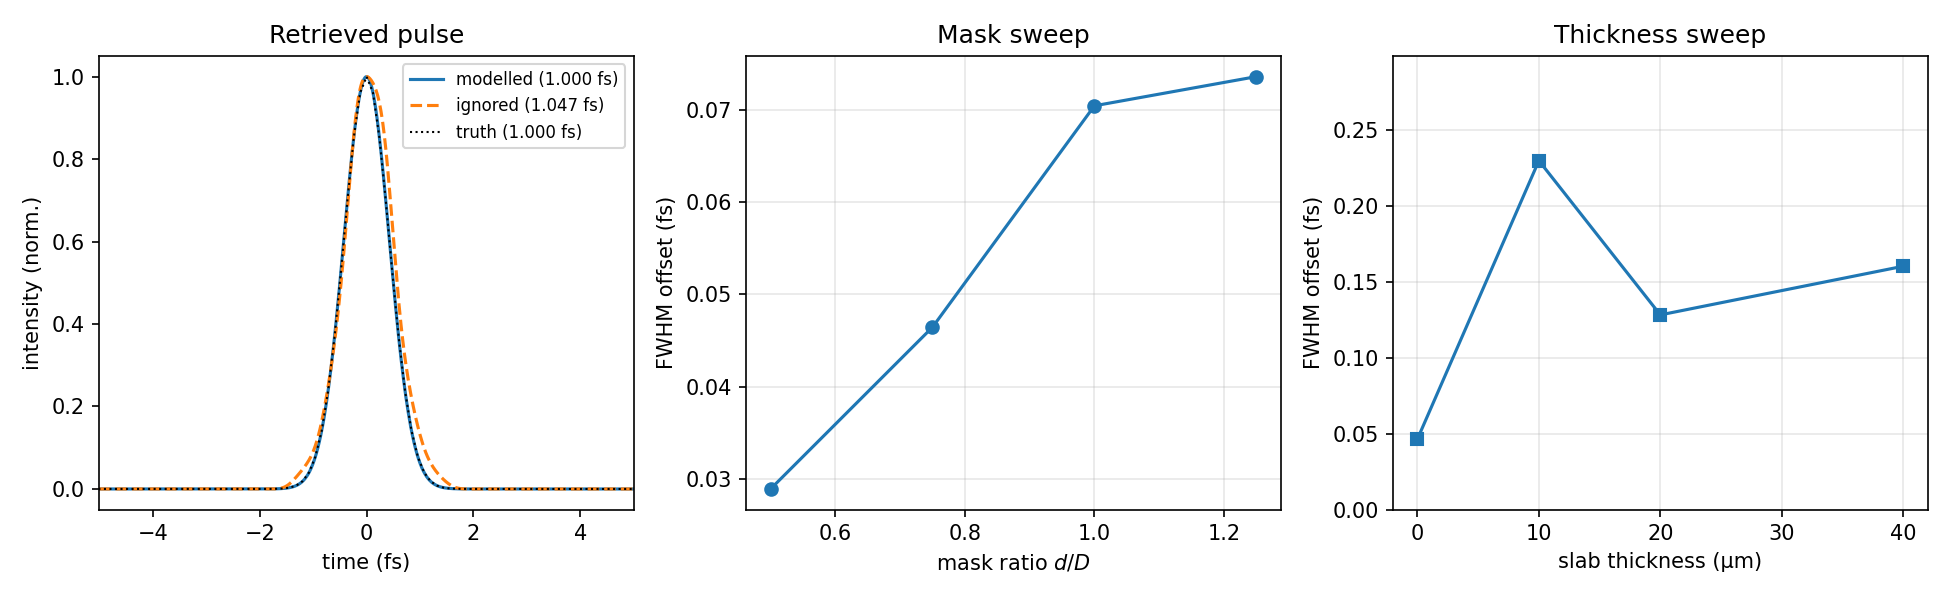

In [3]:
display(Image(filename="geometric_smearing.png"))